# Experiment 2: OOD uncertainty analysis

This notebook analyses the synthetic one-dimensional regression experiment and the Combined Cycle Power Plant experiment. It displays the synthetic prediction figures and compares RMSE, NLL, CRPS, and 90% interval coverage between in-distribution (ID) and out-of-distribution (OOD) observations.

In [47]:
from pathlib import Path

import matplotlib.image as mpimg
import matplotlib.pyplot as plt
from matplotlib.patches import Patch, Rectangle
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", None)
pd.set_option("display.precision", 4)

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RESULT_PATH = PROJECT_ROOT / "results" / "tables" / "experiment_2.csv"
FIGURE_DIRECTORY = PROJECT_ROOT / "results" / "figures" / "experiment_2"

if not RESULT_PATH.exists():
    raise FileNotFoundError(
        f"{RESULT_PATH} does not exist. Run `.venv/bin/python -u "
        "experiments/experiment_2.py` from the project root first."
    )

results = pd.read_csv(RESULT_PATH)
results = results[results["model"] != "mc_dropout_standard"].copy()
METRICS = ["mean_predictive_std", "rmse", "nll", "crps", "coverage_90"]
required_columns = {"dataset", "split", "model", "evaluation_region", *METRICS}
missing = required_columns.difference(results.columns)
if missing:
    raise ValueError(f"Missing required result columns: {sorted(missing)}")

dataset_labels = {
    "synthetic_ood": "Synthetic 1D",
    "power_plant_ood": "Power Plant",
}
preferred_model_order = [
    "exact_gp", "sparse_gp_m16", "sparse_gp_m64",
    "sparse_gp_m256", "deep_ensemble", "mc_dropout", "dkl",
]
available_models = results["model"].dropna().astype(str).unique().tolist()
model_order = [model for model in preferred_model_order if model in available_models]
model_order += sorted(set(available_models).difference(model_order))
model_colors = {
    "exact_gp": "#143163",
    "sparse_gp_m16": "#2A9D8F",
    "sparse_gp_m64": "#87BF2A",
    "sparse_gp_m256": "#7A5195",
    "deep_ensemble": "#910730",
    "mc_dropout": "#E67C13",
    "dkl": "#5E5E5D",
}
model_labels = {
    "exact_gp": "Exact GP",
    "sparse_gp_m16": "Sparse GP (m=16)",
    "sparse_gp_m64": "Sparse GP (m=64)",
    "sparse_gp_m256": "Sparse GP (m=256)",
    "deep_ensemble": "Deep Ensamble",
    "mc_dropout": "MC Dropout",
    "dkl": "DKL",
}
region_order = ["id", "ood"]
results["dataset_label"] = results["dataset"].map(dataset_labels).fillna(results["dataset"])
results["model"] = pd.Categorical(results["model"], model_order, ordered=True)
results["evaluation_region"] = pd.Categorical(
    results["evaluation_region"], region_order, ordered=True
)
print(f"Loaded {len(results):,} regional result rows from {RESULT_PATH}")

Loaded 520 regional result rows from /Users/paulbahde/Desktop/UncertaintyQuantification/results/tables/experiment_2.csv


## 1. PCA direction used for the Power Plant ID/OOD split

The Power Plant split standardizes all four input features before fitting PCA, exactly as in `experiments/experiment_2.py`. The first principal component (PC1) explains **60.96%** of the total standardized input variance. In absolute terms it is dominated by **ambient temperature (AT; loading 0.615, squared-loading share 37.80%)** and **exhaust vacuum (V; 0.560, 31.32%)**. Ambient pressure (AP; -0.404, 16.34%) and relative humidity (RH; -0.381, 14.54%) contribute less. Thus, the tail-based OOD split is primarily a joint temperature/vacuum direction, with pressure and humidity varying in the opposite direction.

PCA component signs are arbitrary: multiplying every loading and every PC1 score by -1 describes the same split. Therefore, component dominance should be interpreted through absolute or squared loadings.

Variance explained by PC1: 60.96%


,feature,description,loading,absolute_loading,squared_loading_share
0,AT,Ambient temperature,+0.6148,0.6148,37.80%
1,V,Exhaust vacuum,+0.5597,0.5597,31.32%
2,AP,Ambient pressure,-0.4042,0.4042,16.34%
3,RH,Relative humidity,-0.3813,0.3813,14.54%


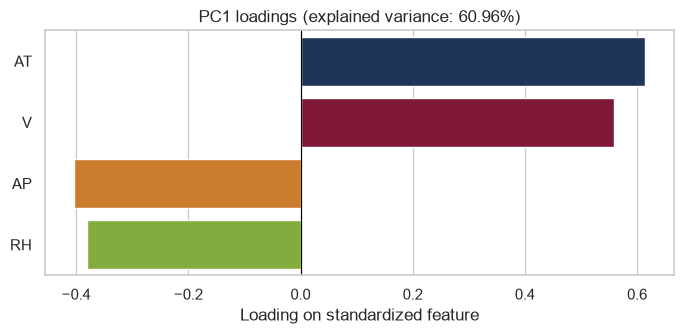

In [48]:
power_plant_cache = PROJECT_ROOT / ".cache" / "uci" / "power_plant_294.npz"
if not power_plant_cache.exists():
    raise FileNotFoundError(
        f"{power_plant_cache} does not exist. Load the Power Plant dataset first."
    )

with np.load(power_plant_cache) as cached:
    X_power_plant = cached["X"]

feature_names = ["AT", "V", "AP", "RH"]
feature_descriptions = [
    "Ambient temperature",
    "Exhaust vacuum",
    "Ambient pressure",
    "Relative humidity",
]
if X_power_plant.shape[1] != len(feature_names):
    raise ValueError("Unexpected number of Power Plant input features")

X_standardized = StandardScaler().fit_transform(X_power_plant)
pca = PCA().fit(X_standardized)
pc1_loadings = pca.components_[0]
loading_table = (
    pd.DataFrame(
        {
            "feature": feature_names,
            "description": feature_descriptions,
            "loading": pc1_loadings,
            "absolute_loading": np.abs(pc1_loadings),
            "squared_loading_share": pc1_loadings**2,
        }
    )
    .sort_values("absolute_loading", ascending=False)
    .reset_index(drop=True)
)

print(f"Variance explained by PC1: {pca.explained_variance_ratio_[0]:.2%}")
display(
    loading_table.style.format(
        {
            "loading": "{:+.4f}",
            "absolute_loading": "{:.4f}",
            "squared_loading_share": "{:.2%}",
        }
    )
)

pca_feature_colors = {
    "AT": "#143163",  # navy
    "V": "#910730",   # burgundy
    "AP": "#E67C13",  # orange
    "RH": "#87BF2A",  # dark gray
}
fig, axis = plt.subplots(figsize=(7, 3.5))
sns.barplot(
    data=loading_table, x="loading", y="feature",
    hue="feature", palette=pca_feature_colors, legend=False, ax=axis,
)
axis.axvline(0, color="black", linewidth=0.8)
axis.set(
    title=f"PC1 loadings (explained variance: {pca.explained_variance_ratio_[0]:.2%})",
    xlabel="Loading on standardized feature", ylabel="",
)
fig.tight_layout()
plt.show()

## 2. Synthetic one-dimensional prediction figures

Each available model has a panel showing its predictive mean and nominal 90% prediction interval together with the true function and fitting observations. The interval visualizes the model's reported predictive uncertainty, and the shaded outer ranges are OOD.

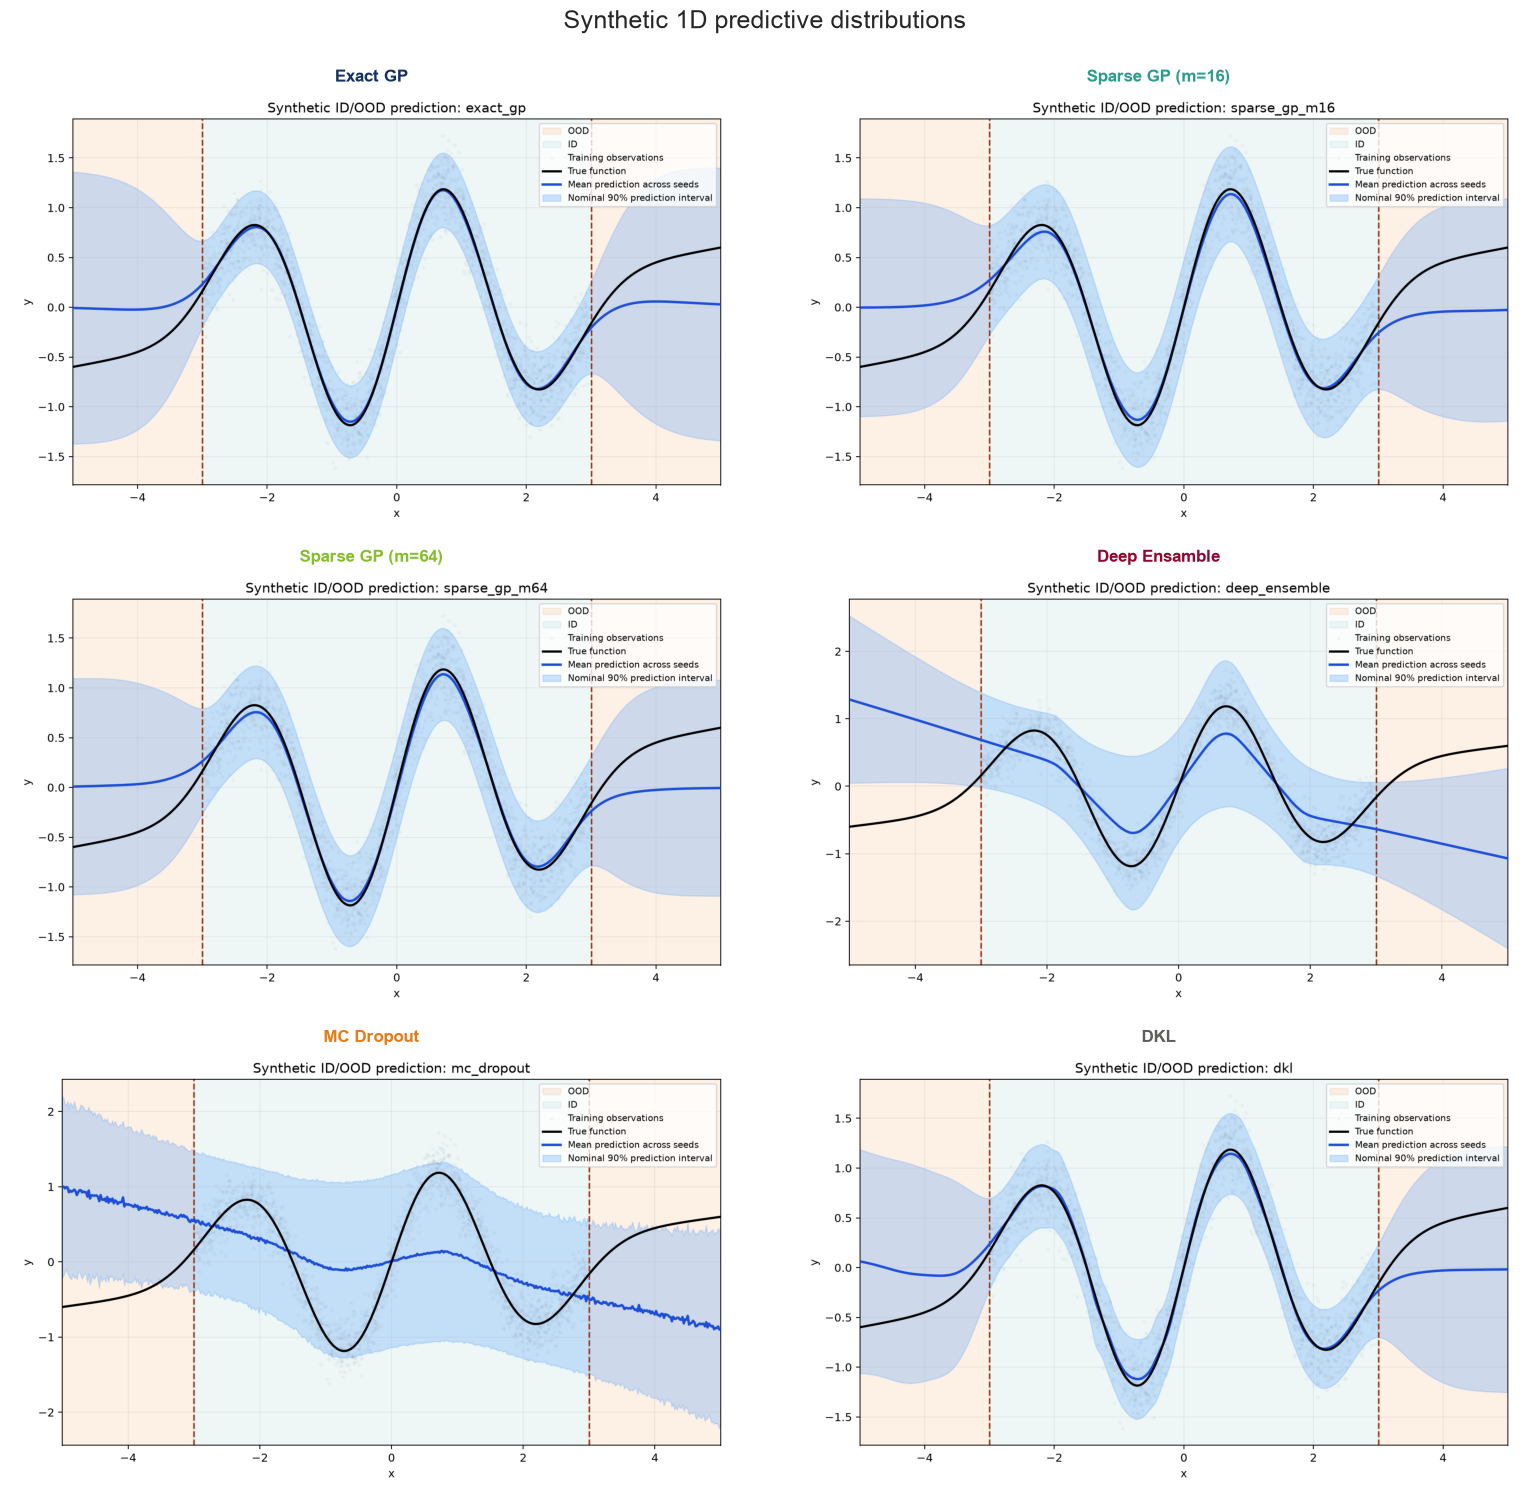

In [49]:
synthetic_models = results.loc[
    results["dataset"] == "synthetic_ood", "model"
].dropna().astype(str).unique()
figure_models = [model for model in model_order if model in synthetic_models]
figure_paths = [FIGURE_DIRECTORY / f"{model}.png" for model in figure_models]
missing_figures = [path for path in figure_paths if not path.exists()]
if missing_figures:
    raise FileNotFoundError(
        "Missing synthetic prediction figures: "
        + ", ".join(path.name for path in missing_figures)
        + ". Run Experiment 2 before executing this notebook."
    )

n_columns = 2
n_rows = int(np.ceil(len(figure_models) / n_columns))
fig, axes = plt.subplots(n_rows, n_columns, figsize=(16, 5 * n_rows), squeeze=False)
for axis, path, model in zip(axes.flat, figure_paths, figure_models):
    axis.imshow(mpimg.imread(path))
    axis.set_title(
        model_labels.get(model, model.replace("_", " ")),
        color=model_colors.get(model, "#333333"), fontweight="bold",
    )
    axis.axis("off")
for axis in axes.flat[len(figure_paths):]:
    axis.axis("off")
fig.suptitle("Synthetic 1D predictive distributions", fontsize=18, y=1.0)
fig.tight_layout()
plt.show()

## 3. Metrics aggregated over seeds

The table reports mean ± sample standard deviation across the 20 seeds. ID and OOD remain separate throughout. Mean predictive standard deviation directly reports the models' predictive uncertainty. Lower is better for RMSE, NLL, and CRPS; coverage is best interpreted relative to the nominal value of 0.90.

In [50]:
summary = (
    results.groupby(
        ["dataset_label", "model", "evaluation_region"],
        observed=True,
    )
    .agg(
        seeds=("split", "nunique"),
        **{
            f"{metric}_{stat}": (metric, stat)
            for metric in METRICS
            for stat in ("mean", "std")
        },
    )
    .reset_index()
    .sort_values(["dataset_label", "model", "evaluation_region"])
)

formatted_summary = summary[["dataset_label", "model", "evaluation_region", "seeds"]].copy()
for metric in METRICS:
    formatted_summary[metric] = summary.apply(
        lambda row: f"{row[f'{metric}_mean']:.4f} ± {row[f'{metric}_std']:.4f}",
        axis=1,
    )


## 4. Side-by-side ID and OOD comparison

Each metric uses one shared figure for both datasets. Within every model, the ID and OOD bars are adjacent. Error bars show one standard deviation across seeds, and the dashed coverage reference marks the nominal 90% target.

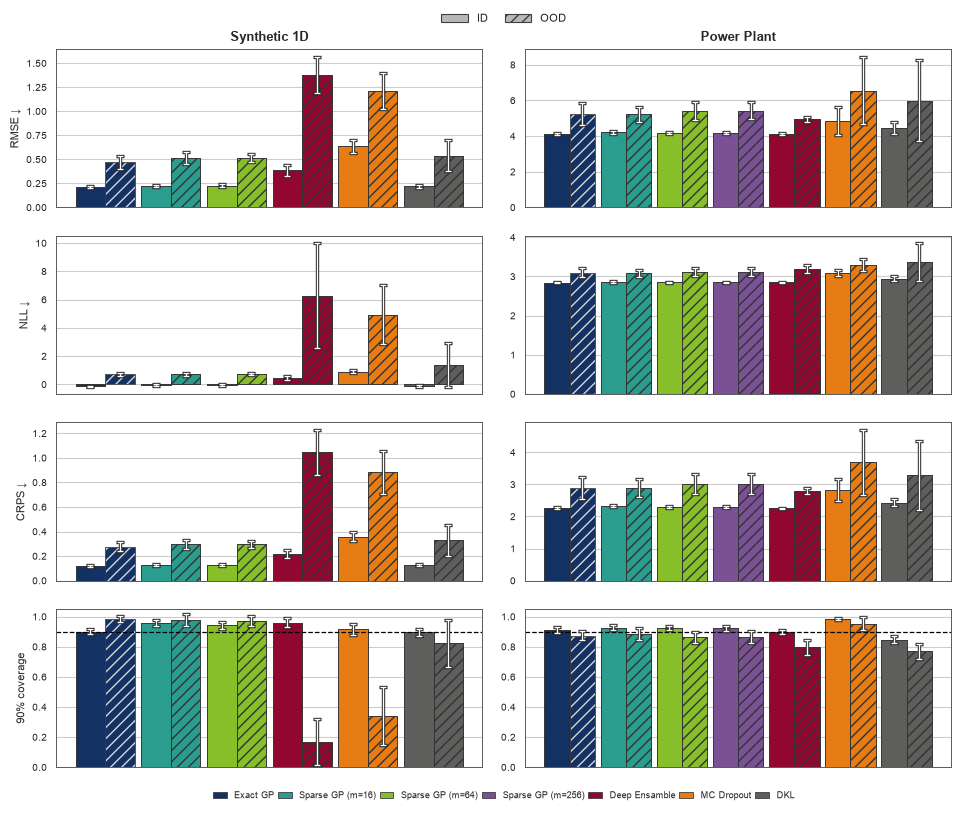

Saved paper figure to /Users/paulbahde/Desktop/UncertaintyQuantification/results/figures/experiment_2/paper_id_ood_metrics.pdf


In [51]:
sns.set_theme(style="whitegrid", context="paper", font_scale=0.9)
metric_labels = {
    "mean_predictive_std": "Mean predictive std. dev.",
    "rmse": "RMSE ↓",
    "nll": "NLL ↓",
    "crps": "CRPS ↓",
    "coverage_90": "90% coverage",
}
region_hatches = {"id": "", "ood": "///"}
region_legend_handles = [
    Patch(
        facecolor="0.72", edgecolor="0.25",
        hatch=region_hatches[region], label=region.upper(),
    )
    for region in region_order
]
plot_metrics = [metric for metric in METRICS if metric != "mean_predictive_std"]
method_legend_handles = [
    Patch(
        facecolor=model_colors[model], edgecolor="#333333",
        linewidth=0.55, label=model_labels.get(model, model),
    )
    for model in model_order
]
dataset_order = [label for label in dataset_labels.values() if label in summary["dataset_label"].unique()]

fig, axes = plt.subplots(
    len(plot_metrics), len(dataset_order),
    figsize=(10.0, 8.3), squeeze=False,
    gridspec_kw={"hspace": 0.18, "wspace": 0.10},
)

for row_index, metric in enumerate(plot_metrics):
    for column_index, dataset_label in enumerate(dataset_order):
        axis = axes[row_index, column_index]
        plot_data = summary[summary["dataset_label"] == dataset_label]
        dataset_model_order = [
            model for model in model_order if model in plot_data["model"].astype(str).unique()
        ]
        sns.barplot(
            data=plot_data, x="model", y=f"{metric}_mean",
            hue="evaluation_region", order=dataset_model_order, hue_order=region_order,
            palette={region: "#BDBDBD" for region in region_order},
            width=0.90, errorbar=None, ax=axis,
        )

        # Keep method colors consistent with Experiment 1; hatch identifies region.
        containers = axis.containers[:len(region_order)]
        for region, container in zip(region_order, containers):
            for model, bar in zip(dataset_model_order, container):
                color = model_colors[model]
                use_light_hatch = region == "ood" and model == "exact_gp"
                bar.set_facecolor(color)
                bar.set_edgecolor("#D6D6D6" if use_light_hatch else "#333333")
                bar.set_linewidth(0.55)
                bar.set_hatch(region_hatches[region])
                # Add a separate dark outline because hatch color follows edge color.
                axis.add_patch(
                    Rectangle(
                        (bar.get_x(), bar.get_y()), bar.get_width(), bar.get_height(),
                        facecolor="none", edgecolor="#333333", linewidth=0.55,
                        zorder=bar.get_zorder() + 0.2,
                    )
                )

        # Add the across-seed standard deviations to the grouped bars.
        for region, container in zip(region_order, containers):
            region_data = (
                plot_data[plot_data["evaluation_region"] == region]
                .set_index("model")
                .reindex(dataset_model_order)
            )
            for bar, std in zip(container, region_data[f"{metric}_std"]):
                if np.isfinite(std):
                    x_center = bar.get_x() + bar.get_width() / 2
                    # Dark halo remains visible above the bar; white center remains
                    # visible while the error bar crosses a dark bar.
                    axis.errorbar(
                        x_center, bar.get_height(), yerr=std, color="#202020",
                        capsize=3, capthick=2.4, linewidth=2.4, zorder=6,
                    )
                    axis.errorbar(
                        x_center, bar.get_height(), yerr=std, color="white",
                        capsize=2, capthick=1.0, linewidth=1.0, zorder=7,
                    )

        if metric == "coverage_90":
            axis.axhline(0.90, color="black", linestyle="--", linewidth=0.9)
            axis.set_ylim(0, 1.05)
        if row_index == 0:
            axis.set_title(dataset_label, fontsize=9.5, fontweight="semibold", pad=6)
        axis.set_xlabel("")
        axis.set_ylabel(
            metric_labels[metric] if column_index == 0 else "", fontsize=8.2,
        )
        axis.tick_params(axis="both", labelsize=7.2, length=3)
        axis.tick_params(axis="x", bottom=False, labelbottom=False)
        legend = axis.get_legend()
        if legend is not None:
            legend.remove()
        for spine in axis.spines.values():
            spine.set_linewidth(0.7)
            spine.set_color("0.35")

plot_center_x = (0.09 + 0.985) / 2
fig.legend(
    handles=region_legend_handles, loc="upper center",
    bbox_to_anchor=(plot_center_x, 0.995), ncol=2, frameon=False,
    columnspacing=1.5, handlelength=2.4, fontsize=8.0,
)
fig.legend(
    handles=method_legend_handles, loc="lower center",
    bbox_to_anchor=(plot_center_x, 0.025), ncol=len(method_legend_handles), frameon=False,
    columnspacing=0.40, handlelength=1.45, fontsize=6.8,
)
fig.subplots_adjust(top=0.94, bottom=0.075, left=0.09, right=0.985)
FIGURE_DIRECTORY.mkdir(parents=True, exist_ok=True)
paper_figure_base = FIGURE_DIRECTORY / "paper_id_ood_metrics"
fig.savefig(paper_figure_base.with_suffix(".pdf"), bbox_inches="tight")
fig.savefig(paper_figure_base.with_suffix(".png"), dpi=300, bbox_inches="tight")
plt.show()
print(f"Saved paper figure to {paper_figure_base.with_suffix('.pdf')}")

## 5. Synthetic prediction-figure design sandbox

The next cell contains a notebook-local copy of `PredictionCollector.save_figures` from `experiments/experiment_2.py`. Edit this copy to prototype the design without changing the experiment or retraining models. Preview files are written to a separate `design_preview` directory.

In [52]:
DESIGN_PREVIEW_DIRECTORY = FIGURE_DIRECTORY / "design_preview"
DESIGN_TEST_BOUND = 5.0
DESIGN_TRAIN_BOUND = 3.0

def design_latent_function(x):
    """Notebook-local copy of the Experiment 2 synthetic function."""
    x = np.asarray(x)
    return (
        0.12 * x
        + 1.2 * np.exp(-0.5 * ((x + 2.1) / 0.7) ** 2)
        - 1.4 * np.exp(-0.5 * ((x + 0.7) / 0.65) ** 2)
        + 1.4 * np.exp(-0.5 * ((x - 0.7) / 0.65) ** 2)
        - 1.2 * np.exp(-0.5 * ((x - 2.1) / 0.7) ** 2)
    )

class PredictionFigureDesignSandbox:
    """Small stand-in exposing an editable copy of save_figures."""

    def __init__(self, output_directory=DESIGN_PREVIEW_DIRECTORY):
        self.output_directory = Path(output_directory)
        self.grid = np.linspace(
            -DESIGN_TEST_BOUND, DESIGN_TEST_BOUND, 500
        ).reshape(-1, 1)
        self.predictions = {}
        self.training_sets = {}

    def save_figures(self):
        """Editable copy of PredictionCollector.save_figures."""
        self.output_directory.mkdir(parents=True, exist_ok=True)
        output_paths = []
        for model_name, predictions in self.predictions.items():
            means = np.stack([mean for mean, _ in predictions])
            variances = np.stack([variance for _, variance in predictions])
            mixture_mean = np.mean(means, axis=0)
            mixture_variance = (
                np.mean(variances + means ** 2, axis=0) - mixture_mean ** 2
            )
            interval_radius = 1.6448536269514722 * np.sqrt(
                np.maximum(mixture_variance, 1e-12)
            )

            # Figure-design block: edit the settings below and rerun the test cell.
            figure, axis = plt.subplots(figsize=(8.0, 4.6))
            figure.patch.set_facecolor("white")
            axis.set_facecolor("white")
            axis.plot(
                self.grid[:, 0], design_latent_function(self.grid[:, 0]),
                color="black", linewidth=1.7, label="True function", zorder=5,
            )
            axis.plot(
                self.grid[:, 0], mixture_mean, color="#910730",
                linewidth=1.8, label="Mean prediction across seeds", zorder=4,
            )
            axis.fill_between(
                self.grid[:, 0], mixture_mean - interval_radius,
                mixture_mean + interval_radius, color="#910730", alpha=0.16,
                label="Nominal 90% prediction interval", zorder=1,
            )
            axis.axvline(
                -DESIGN_TRAIN_BOUND, color="#143163",
                linestyle=(0, (4, 2)), linewidth=1.2,
                label="ID/OOD boundary", zorder=3,
            )
            axis.axvline(
                DESIGN_TRAIN_BOUND, color="#143163",
                linestyle=(0, (4, 2)), linewidth=1.2, zorder=3,
            )
            axis.set(
                xlim=(-DESIGN_TEST_BOUND, DESIGN_TEST_BOUND),
                xlabel="Input x", ylabel="Target y",
            )
            axis.xaxis.label.set_size(8.2)
            axis.yaxis.label.set_size(8.2)
            axis.tick_params(axis="both", labelsize=7.5, length=3)
            axis.grid(True, which="major", color="0.88", linewidth=0.55)
            axis.grid(False, which="minor")
            for spine in axis.spines.values():
                spine.set_linewidth(0.7)
                spine.set_color("0.35")
            handles, labels = axis.get_legend_handles_labels()
            unique = dict(zip(labels, handles))
            figure.legend(
                unique.values(), unique.keys(), loc="upper center",
                bbox_to_anchor=(0.5, 0.99), ncol=len(unique), frameon=False,
                columnspacing=1.0, handlelength=2.2, fontsize=7.5,
            )
            figure.subplots_adjust(top=0.87, bottom=0.14, left=0.10, right=0.985)

            output_path = self.output_directory / f"{model_name}.png"
            pdf_path = self.output_directory / f"{model_name}.pdf"
            figure.savefig(output_path, dpi=300, bbox_inches="tight")
            figure.savefig(pdf_path, bbox_inches="tight")
            plt.close(figure)
            output_paths.append(output_path)
        return output_paths

### Test the copied method

This deterministic fixture mimics five fitted seeds. It tests the complete aggregation and rendering path, then displays the generated preview inline.

Design preview saved to /Users/paulbahde/Desktop/UncertaintyQuantification/results/figures/experiment_2/design_preview/exact_gp_design_preview.png


/Users/paulbahde/Desktop/UncertaintyQuantification/results/figures/experiment_2/design_preview/exact_gp_design_preview.png

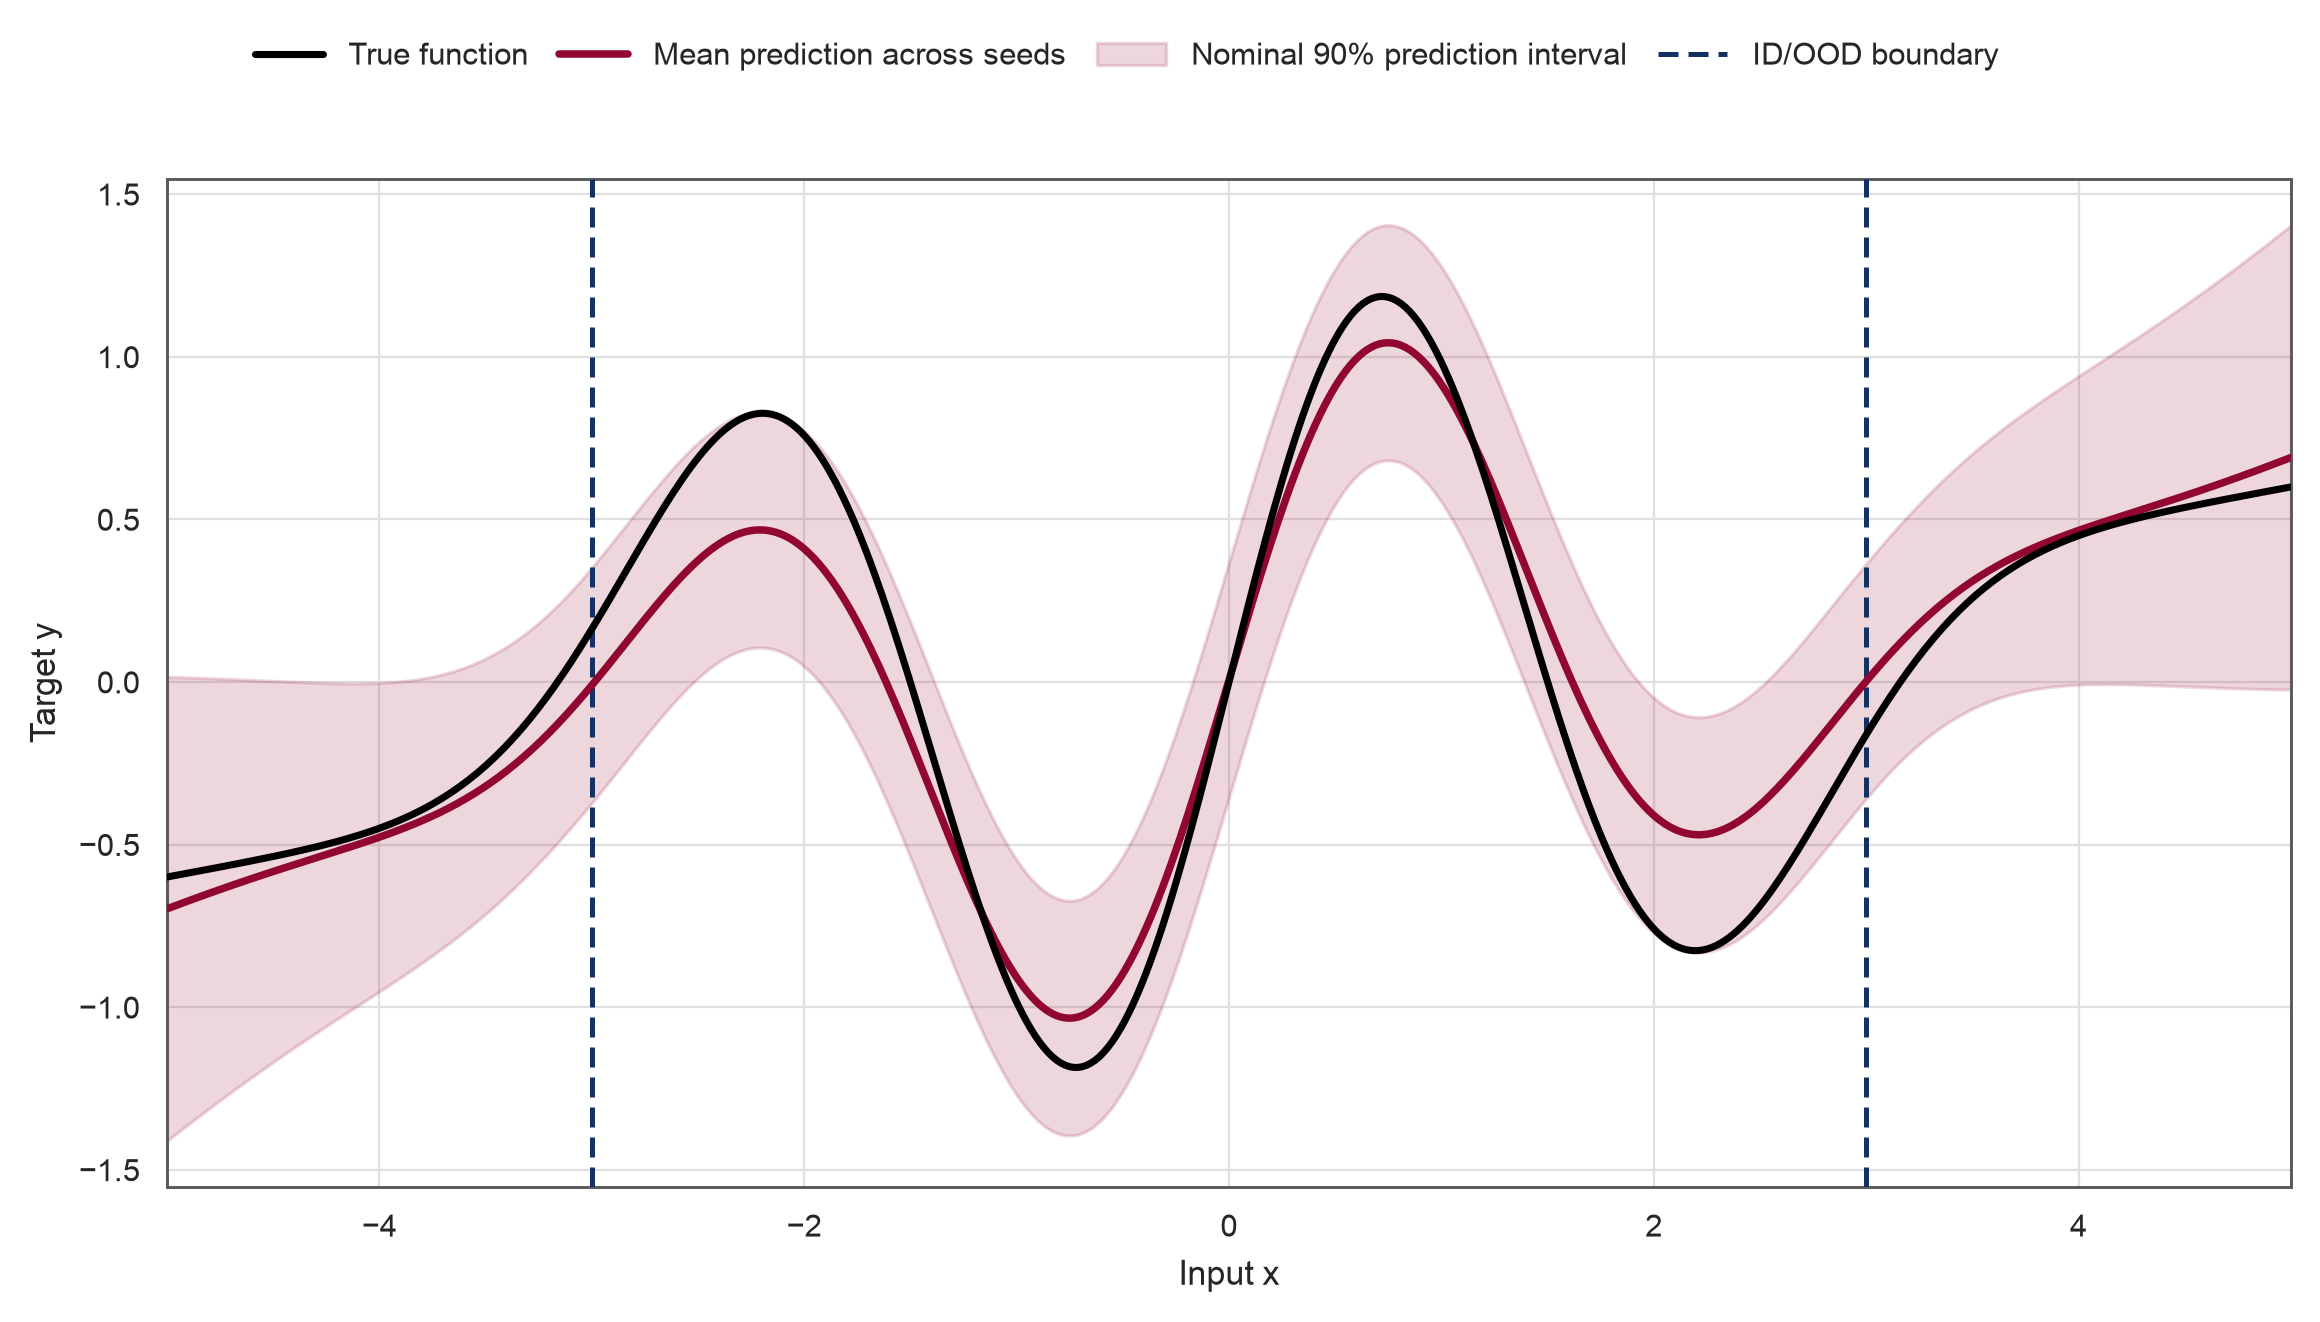

In [53]:
from IPython.display import FileLink, Image

preview = PredictionFigureDesignSandbox()
preview_model_name = "exact_gp_design_preview"
preview.predictions[preview_model_name] = []

for split_idx in range(5):
    x_grid = preview.grid[:, 0]
    # Deliberately imperfect prediction: attenuated peaks, smooth bias,
    # and a small seed-specific perturbation.
    mean = (
        0.78 * design_latent_function(x_grid)
        + 0.10 * np.sin(1.15 * x_grid)
        + 0.055 * x_grid
        + 0.025 * np.sin(0.8 * x_grid + split_idx)
    )
    variance = (
        0.2 ** 2
        + 0.035 * np.maximum(np.abs(x_grid) - DESIGN_TRAIN_BOUND, 0) ** 2
        + 0.004 * split_idx
    )
    preview.predictions[preview_model_name].append((mean, variance))

preview_paths = preview.save_figures()
preview_path = preview_paths[0]
print(f"Design preview saved to {preview_path}")
display(FileLink(preview_path))
display(Image(filename=str(preview_path)))